# MECHA in metafspm, 4: a whole plant in its soil

The components of the previous tutorials on a whole seedling in a soil column, as metafspm's
soil–plant–atmosphere example: water from the water table through the soil, into every root section's cells and
walls, up the xylem of the roots, the stem and the leaves, and out through the stomata.

The seedling's architecture, the stand-in for root development, metafspm's soil model and the plant–soil links
come from `example/soil_plant_atmosphere/seedling_spac.py`; the plant model is assembled here.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator
from openalea.metafspm.scene.scene import Scene

from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha.component import MechaHydraulics
from openalea.mecha.osmotic import MechaOsmoticPresets

sys.path.insert(0, os.path.join(os.path.abspath(""), "..", "soil_plant_atmosphere"))
from seedling_spac import (SCENE_TRANSLATOR, Soil, SeedlingArchitecture, development, largest_change,  # noqa: E402
                           root_surface_mappings)
import plots as spac_plots                                                                              # noqa: E402

## 1. The plant model

As `GrassBRIDGES.__init__` in Wheat-BRIDGES: the components instantiated on the plant's DataStructure, then coupled.

- `SeedlingArchitecture` gives every segment its geometry (radius, length, 3D extent for the soil mapping);
- `GranapAnatomy` gives roots, stems and leaves their anatomies (the scenario's `stem_anatomy` and `leaf_anatomy`
  turn the shoot's on);
- `MechaOsmoticPresets` stands for a solute model (the root cells' osmotic potentials);
- `MechaHydraulics` solves the plant problem on every section; each leaf organ's transpiration is an Organ-scale
  input, set before it is built (a constant share of the plant's for now);
- at each step, `development` gives the barriers (by distance from the tips), a root development model's role.

In [2]:
class Seedling(CompositeModel):
    initiators = (SeedlingArchitecture, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules

    def __init__(self, data_structure, time_step, transpiration=0.015):
        ds = data_structure
        self.architecture = SeedlingArchitecture(data_structure=ds, time_step=time_step)
        self.anatomy = GranapAnatomy(data_structure=ds, time_step=time_step)
        self.osmotic = MechaOsmoticPresets(data_structure=ds, time_step=time_step)
        g, organs = ds.mtg, [int(v) for v in ds.entity_ids("Organ")]
        leaves = [v for v in organs if g.property("label")[v] == g.labels.Organ.Leaf]
        for v in organs:                                               # mm3 s-1 shared by the leaves, in cm3 d-1
            g.property("leaf_transpiration")[v] = transpiration * 86.4 / len(leaves) if v in leaves else 0.
        self.hydraulics = MechaHydraulics(data_structure=ds, time_step=time_step)
        self.declare_data_and_couple_components(
            translator_path=Translator(), components=(self.architecture, self.anatomy, self.osmotic, self.hydraulics))
        ds.define_mask("root_surface", {"soil_conductance": ">0"})     # where the soil mapping applies

    def run(self):
        ds = self.hydraulics.data_structure
        self.anatomy()
        roots = list(self.hydraulics.section_roles()[1])
        is_root = np.isin(ds.entity_ids("SubOrgan")[ds.owner("SubOrgan")], roots)
        ds.set("barrier", development(ds, is_root))
        self.osmotic()
        self.hydraulics()

## 2. The scene

The planting table gives the seedling its scenario: the shoot's anatomies on, no condition at the collar (the
shoot is above the roots; the leaves' transpiration drives the flow), and the plant's transpiration.

The soil (metafspm's `Soil`, a 3D grid solving Richards' equation) is an environment model. The `Translator`
links it to the plant across names and units: the soil's `water_potential` (MPa) is MECHA's `soil_psi` (hPa),
MECHA's `root_uptake` (cm³ d⁻¹) the soil's `plant_uptake` (mm³ s⁻¹). The mapping overlaps the roots' surface nodes
with the soil's voxels. The scene steps the plant and the soil in turn until the water potentials stop changing.

In [3]:
for link in SCENE_TRANSLATOR.links_of("MechaHydraulics", "SoilWaterTransport") + \
        SCENE_TRANSLATOR.links_of("SoilWaterTransport", "MechaHydraulics"):
    print(f"{link.receiver}.{link.variable} = " + " + ".join(f"{factor:g} × {link.provider}.{name}"
                                                             for name, factor in link.sources.items()))

scenario = {"parameters": {"stem_anatomy": {}, "leaf_anatomy": {}, "collar_condition": 0.}, "transpiration": 0.015}
table = pd.DataFrame([dict(plant="seedling", model=Seedling, x=0.1, y=0.1, z=0., rotation=0., scenario=scenario)])
table.attrs.update(xrange=0.2, yrange=0.2)                            # a 0.2 m x 0.2 m soil column
stop = largest_change(1e-4)
scene = Scene(table, environment=[Soil], environment_scenarios=[{}], translator=SCENE_TRANSLATOR, time_step=3600,
              mappings=root_surface_mappings, stop_when=stop)
plant = scene.populations[0].data_structure
print(f"{len(plant.entity_ids('SubOrgan'))} sections, {plant.n_nodes()} Compartments, {plant.n_edges()} Connections")

MechaHydraulics.soil_psi = 10000 × SoilWaterTransport.water_potential
SoilWaterTransport.plant_uptake = 0.0115741 × MechaHydraulics.root_uptake


48 sections, 523509 Compartments, 1291965 Connections


## 3. Run to the fixed point

In [4]:
scene.simulate(30)
soil = next(model for model in scene.environment if isinstance(model, Soil)).grid
print(f"{scene.iteration} steps; largest change of Ψ per step (MPa):",
      ", ".join(f"{change:.1e}" for change in stop.history))
pd.Series({"transpiration (mm³ s⁻¹)": plant.get("evaporation").sum() / 86.4,
           "root uptake (mm³ s⁻¹)": plant.get("root_uptake").sum() / 86.4,
           "taken from the soil (mm³ s⁻¹)": soil.get("plant_uptake").sum(),
           "lowest liquid ψ (MPa)": plant.get("water_potential")[plant.get("vapour_node") == 0].min() / 1e4})

5 steps; largest change of Ψ per step (MPa): inf, 8.2e-01, 8.5e-03, 7.9e-04, 7.2e-05


transpiration (mm³ s⁻¹)          0.015000
root uptake (mm³ s⁻¹)            0.015000
taken from the soil (mm³ s⁻¹)    0.015000
lowest liquid ψ (MPa)           -0.943332
dtype: float64

## 4. The results

The example's figures: the plant over the soil's potential; the potential along the water's path; a section of
each organ; the roots' kr; the potentials upscaled from the Compartments to the plant.

In [5]:
folder = os.path.join(os.path.abspath(""), "outputs", "tutorial_04")
spac_plots.all_figures(scene, folder)

ψ upscaled (MPa): Compartment 523509 [-11.31, -0.62], SubOrgan 48 [-0.86, -0.65], Organ 13 [-0.84, -0.74], Phytomer 6 [-0.83, -0.76], GrowthUnit 4 [-0.83, -0.76], Axis 4 [-0.83, -0.76], Plant 1 [-0.80, -0.80]


ψ by tissue (MPa; organ, tissue, nodes, mean, min):


  root  air space                      10643  -0.813  -0.872
  root  cortex                          5974  -0.815  -0.873
  root  endodermis                       928  -0.874  -0.901
  root  epidermis                       4872  -0.807  -0.861
  root  exodermis                       2291  -0.807  -0.861
  root  metaxylem                        145  -0.929  -0.930
  root  pericycle                       2813  -0.926  -0.940
  root  phloem                           290  -0.930  -0.937
  root  protoxylem                       290  -0.928  -0.943
  root  stele                          11774  -0.928  -0.941
  root  apoplast (walls, junctions)   199781  -0.817  -0.943
  stem  air space                       1647  -0.758  -0.773
  stem  companion cell                   477  -0.756  -0.775
  stem  cortex                          1365  -0.759  -0.774
  stem  epidermis                        783  -0.759  -0.768
  stem  parenchyma                     11490  -0.756  -0.776
  stem  sclerenchyma    

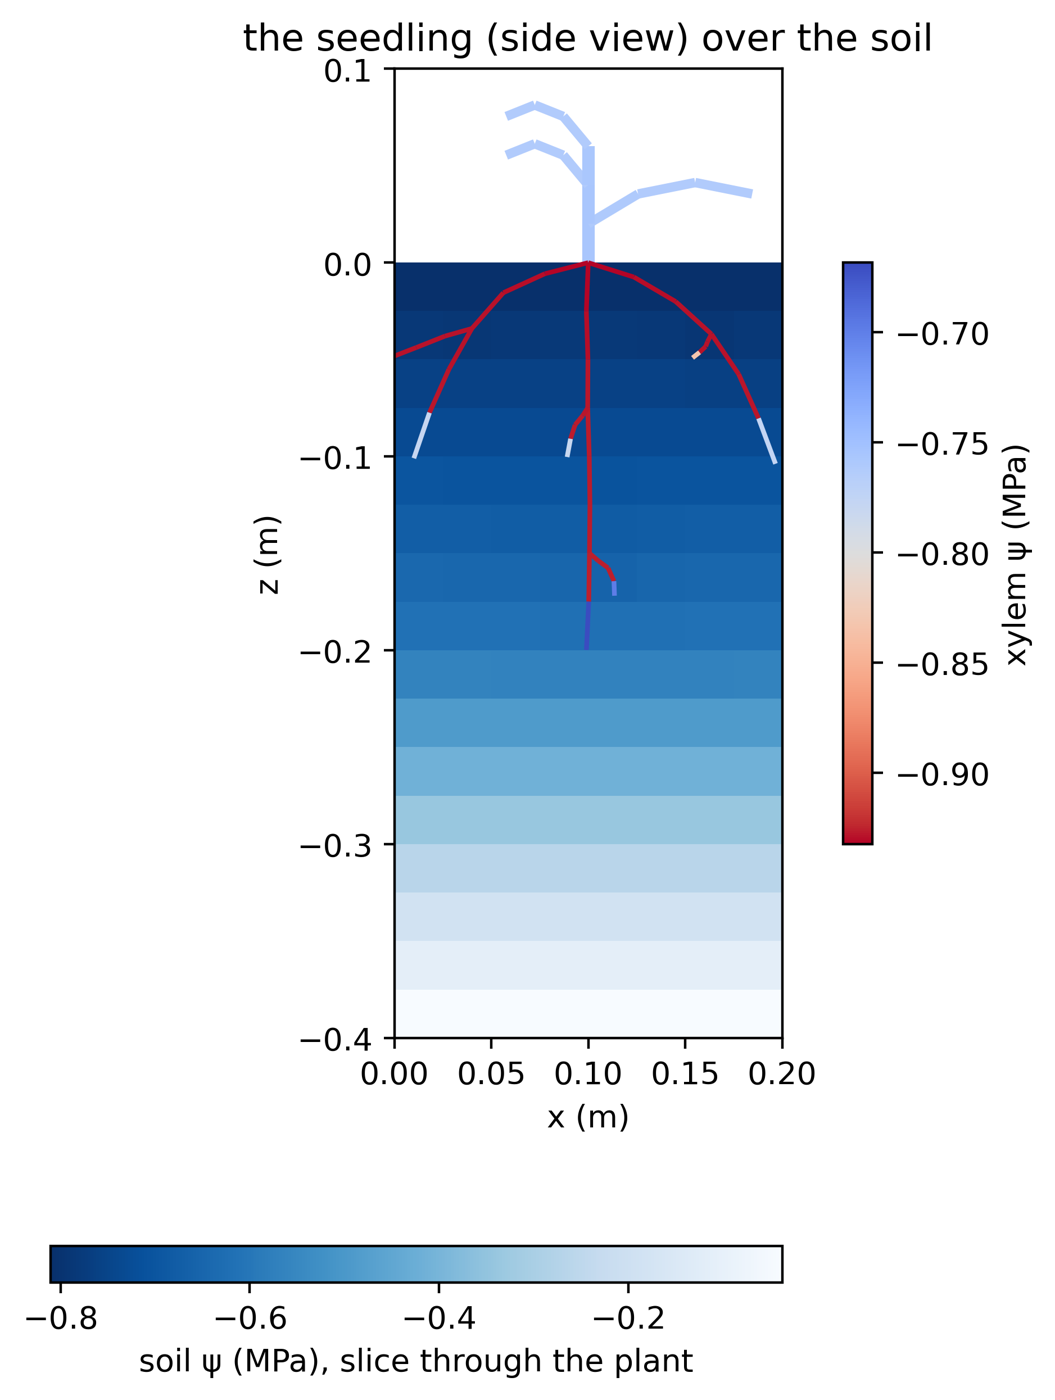

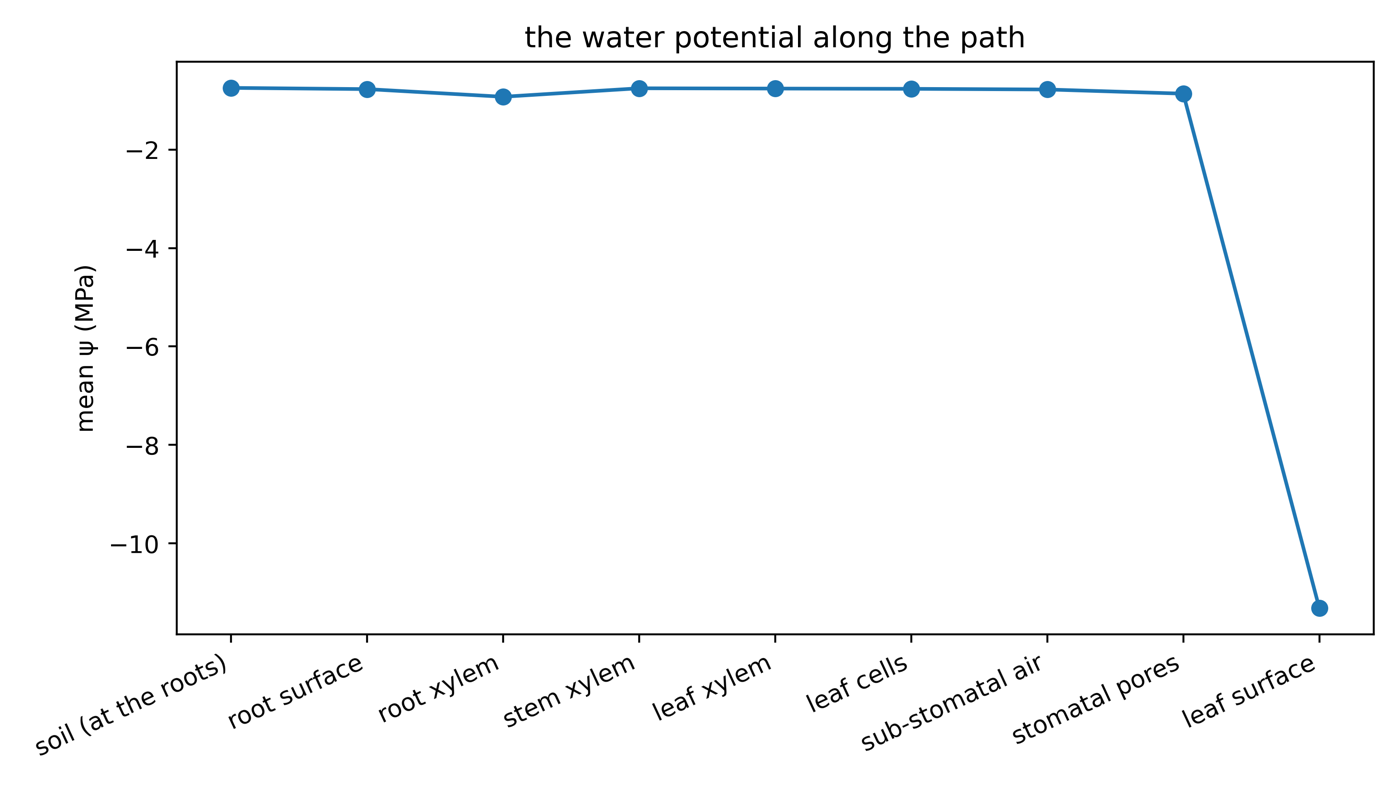

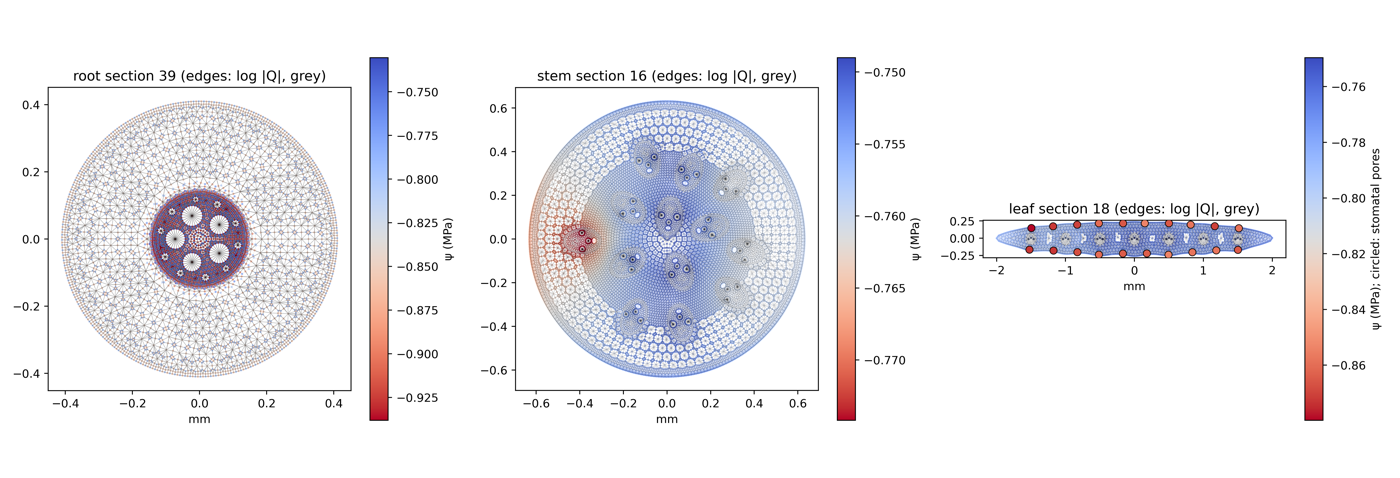

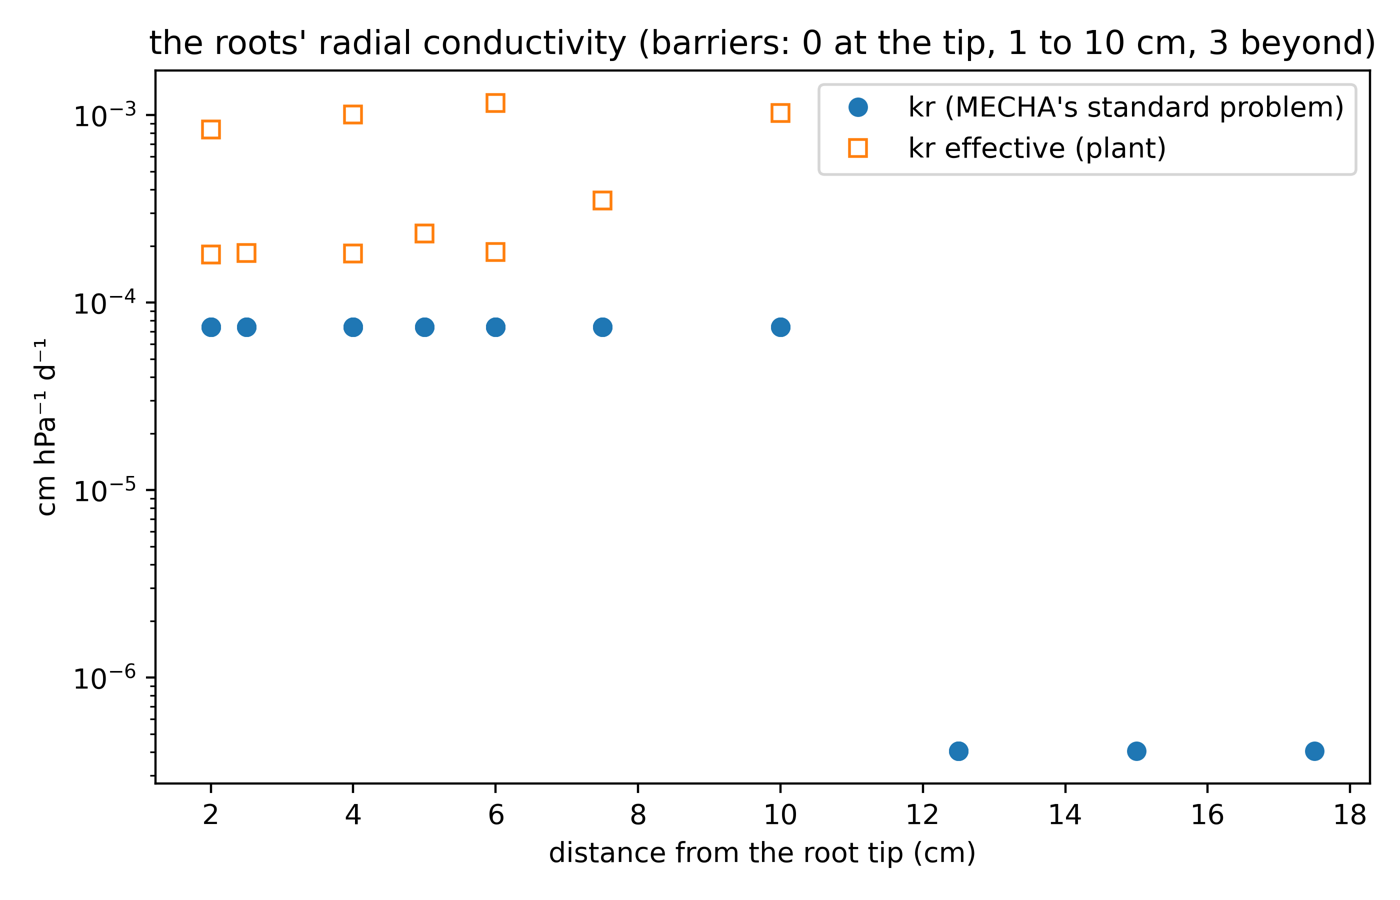

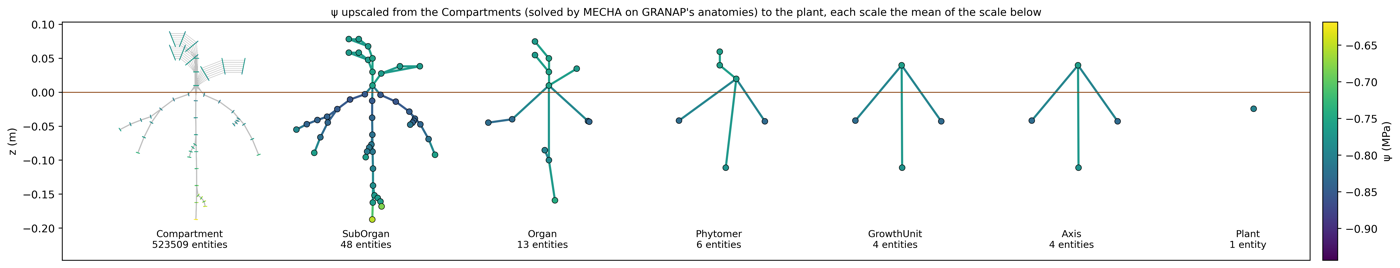

In [6]:
import io
from PIL import Image as PILImage

for name in ("plant_over_soil", "potential_profile", "sections_by_organ", "root_kr", "upscaling"):
    picture = PILImage.open(os.path.join(folder, f"{name}.png"))
    picture.thumbnail((1400, 1400))                                   # the files are 300 dpi
    buffer = io.BytesIO()
    picture.save(buffer, format="png", optimize=True)
    display(Image(data=buffer.getvalue(), width=900))